In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from tqdm import tqdm

# Load the dataset
df = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv")

# Parse the standardized features
df['Combined_Features'] = df['Combined_Features'].apply(eval)

# Convert features to a NumPy array
X = np.array(df['Combined_Features'].tolist())
y = df['Class_Label'].values

# Define the objective function for feature selection
def objective_function(mask):
    selected_features = np.where(mask > 0.5)[0]
    if len(selected_features) == 0:
        return 1.0  # Penalize empty feature subsets
    X_selected = X[:, selected_features]
    X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.3, random_state=42)
    clf = RandomForestClassifier()
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    return 1 - accuracy  # Minimize the inverse of accuracy

# Define the LION Optimizer
class LIONOptimizer:
    def __init__(self, obj_func, dim, bounds, max_iter, population_size, leader_ratio=0.2):
        self.obj_func = obj_func
        self.dim = dim
        self.bounds = bounds
        self.max_iter = max_iter
        self.population_size = population_size
        self.leader_ratio = leader_ratio
        self.population = np.random.uniform(bounds[0], bounds[1], (population_size, dim))
        self.leader_count = int(population_size * leader_ratio)

    def optimize(self):
        fitness = np.array([self.obj_func(ind) for ind in self.population])
        best_solution = self.population[np.argmin(fitness)]
        best_fitness = np.min(fitness)

        for iter_num in tqdm(range(self.max_iter), desc="Optimizing"):
            # Sort population based on fitness
            sorted_indices = np.argsort(fitness)
            leaders = self.population[sorted_indices[:self.leader_count]]
            imitators = self.population[sorted_indices[self.leader_count:]]

            # Leaders explore
            for i in range(self.leader_count):
                exploration = np.random.uniform(-0.5, 0.5, self.dim)
                self.population[sorted_indices[i]] = np.clip(leaders[i] + exploration, self.bounds[0], self.bounds[1])

            # Imitators follow
            for i in range(len(imitators)):
                leader_choice = leaders[np.random.randint(0, self.leader_count)]  # Pick a random leader row
                imitation = np.random.uniform(0, 1, self.dim)
                self.population[sorted_indices[self.leader_count + i]] = np.clip(leader_choice * imitation + imitators[i] * (1 - imitation), self.bounds[0], self.bounds[1])

            # Recalculate fitness
            fitness = np.array([self.obj_func(ind) for ind in self.population])
            current_best = np.min(fitness)
            if current_best < best_fitness:
                best_solution = self.population[np.argmin(fitness)]
                best_fitness = current_best

        return best_solution, best_fitness

# Set parameters
dim = X.shape[1]
bounds = [0, 1]
max_iter = 100
population_size = 20

# Initialize and run the LION optimizer
lion_optimizer = LIONOptimizer(objective_function, dim, bounds, max_iter, population_size)
best_mask, best_fitness = lion_optimizer.optimize()

# Extract the selected features
selected_features = np.where(best_mask > 0.5)[0]
df['Selected_Features'] = df['Combined_Features'].apply(lambda x: [x[i] for i in selected_features])

# Save the new CSV
df[['Image_Index', 'Class_Label', 'Selected_Features']].to_csv('LION_selected_features.csv', index=False)

print("Feature selection completed using LION optimizer and new dataset saved!")

Optimizing: 100%|██████████| 100/100 [07:39<00:00,  4.59s/it]

Feature selection completed using LION optimizer and new dataset saved!


In [3]:
import pandas as pd

# Load original and selected datasets
original_df = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv")
selected_df = pd.read_csv('LION_selected_features.csv')

# Extract and count features
original_features_count = len(eval(original_df['Combined_Features'][0]))
selected_features_count = len(eval(selected_df['Selected_Features'][0]))

# Compare number of features
print(f"Original number of features: {original_features_count}")
print(f"Selected number of features: {selected_features_count}")

reduction_percentage = ((original_features_count - selected_features_count) / original_features_count) * 100
print(f"Feature reduction: {reduction_percentage:.2f}%")

Original number of features: 199
Selected number of features: 98
Feature reduction: 50.75%


# ML

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, Flatten, MaxPooling1D, Dropout
import matplotlib.pyplot as plt
import seaborn as sns

# Load CSV
data = pd.read_csv("LION_selected_features.csv")

# Parse features
features = data['Selected_Features'].apply(lambda x: np.array(eval(x))).tolist()
X = np.array(features)
y = data['Class_Label']

# Encode class labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Helper function to evaluate models
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='weighted'))
    print("Recall:", recall_score(y_test, y_pred, average='weighted'))
    print("F1 Score:", f1_score(y_test, y_pred, average='weighted'))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')
    plt.show()

Accuracy: 0.7979274611398963
Precision: 0.8167593860980024
Recall: 0.7979274611398963
F1 Score: 0.7916452121279195
Confusion Matrix:
 [[35  2  0  0  3  0]
 [ 0 24  0  0  3  0]
 [14  0 16  2  1  0]
 [ 0  0  1 32  0  0]
 [ 2  0  0  0 20  8]
 [ 0  0  0  0  3 27]]


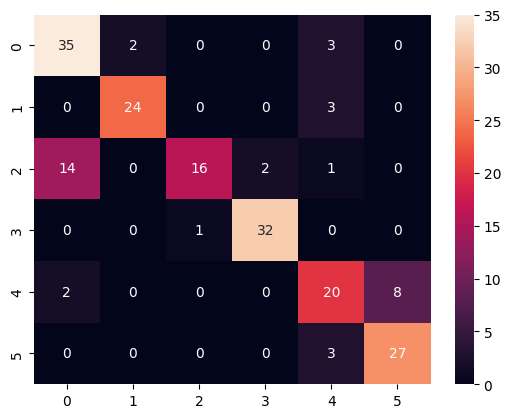

In [2]:
# 1. Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
evaluate_model(nb_model, X_test, y_test)

Accuracy: 0.9481865284974094
Precision: 0.9489257368537497
Recall: 0.9481865284974094
F1 Score: 0.9482495722898836
Confusion Matrix:
 [[38  0  2  0  0  0]
 [ 0 25  1  0  1  0]
 [ 1  1 31  0  0  0]
 [ 0  0  0 33  0  0]
 [ 0  0  0  0 27  3]
 [ 0  0  0  0  1 29]]


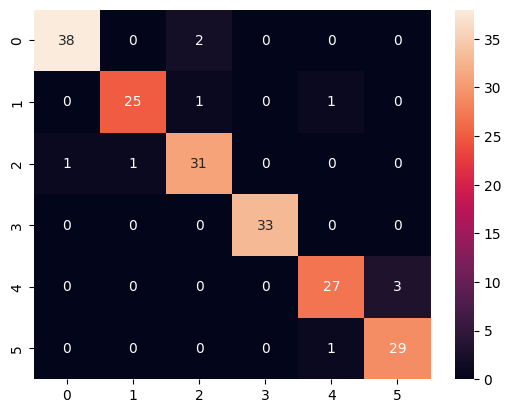

In [3]:
# 2. Support Vector Machine
svm_model = SVC()
svm_model.fit(X_train, y_train)
evaluate_model(svm_model, X_test, y_test)

Accuracy: 0.8031088082901554
Precision: 0.80724376794276
Recall: 0.8031088082901554
F1 Score: 0.803900467931758
Confusion Matrix:
 [[31  2  5  0  2  0]
 [ 1 22  0  0  2  2]
 [ 8  0 23  2  0  0]
 [ 1  0  2 30  0  0]
 [ 4  0  1  0 22  3]
 [ 0  0  0  0  3 27]]


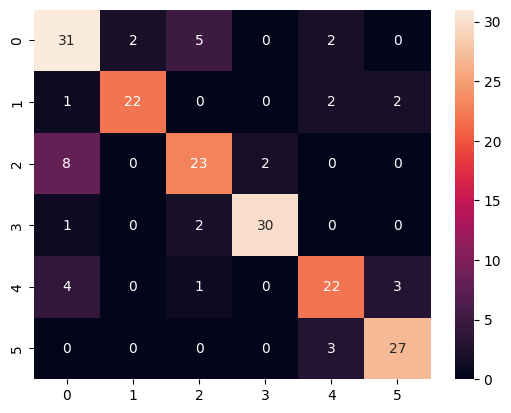

In [4]:
# 3. Decision Tree
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)
evaluate_model(dt_model, X_test, y_test)

Accuracy: 0.9378238341968912
Precision: 0.938356470681509
Recall: 0.9378238341968912
F1 Score: 0.9377106827263981
Confusion Matrix:
 [[39  1  0  0  0  0]
 [ 0 26  0  0  1  0]
 [ 2  0 30  1  0  0]
 [ 0  0  3 30  0  0]
 [ 0  0  0  0 27  3]
 [ 0  0  0  0  1 29]]


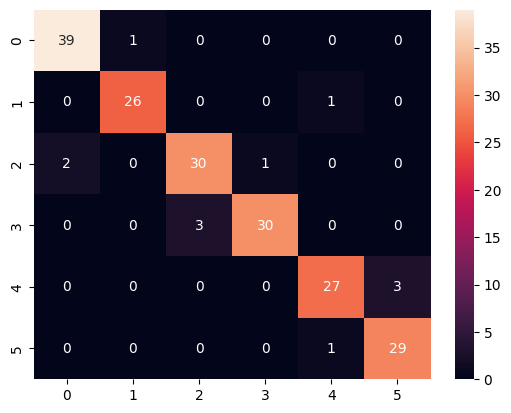

In [5]:
# 4. Random Forest
rf_model = RandomForestClassifier()
rf_model.fit(X_train, y_train)
evaluate_model(rf_model, X_test, y_test)

/Users/kshitijsharma/ml_envs/tensorflow-gpu/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-03-21 14:27:48.184111: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Pro
2025-03-21 14:27:48.184139: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-03-21 14:27:48.184145: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-03-21 14:27:48.184161: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-03-21 14:27:48.184170: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_fa

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 146ms/step - accuracy: 0.8865 - loss: 0.3299
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Accuracy: 0.8860103626943006
Precision: 0.8955958549222798
Recall: 0.8860103626943006
F1 Score: 0.8850265044066736
Confusion Matrix:
 [[37  0  3  0  0  0]
 [ 2 22  0  0  2  1]
 [ 1  0 27  3  1  1]
 [ 0  0  0 33  0  0]
 [ 0  0  0  0 22  8]
 [ 0  0  0  0  0 30]]


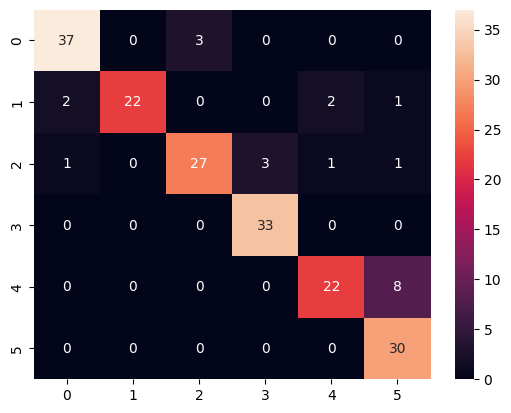

In [6]:
# 5. Artificial Neural Network

def evaluate_model(model, X_test, y_test, labels=None):
    # Handle ANN/CNN differently — check if output is probabilistic
    y_pred = model.predict(X_test)
    if len(y_pred.shape) > 1 and y_pred.shape[1] > 1:
        y_pred = np.argmax(y_pred, axis=1)  # Convert softmax output to class labels
    
    # Compute metrics
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
    print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))
    
    # Ensure confusion matrix includes all labels even if missing in predictions
    cm = confusion_matrix(y_test, y_pred, labels=labels if labels else np.unique(y_test))
    print("Confusion Matrix:\n", cm)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.show()

ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])
ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
ann_model.fit(X_train, y_train, epochs=20, batch_size=16, verbose=0)
ann_eval = ann_model.evaluate(X_test, y_test)
y_pred_ann = np.argmax(ann_model.predict(X_test), axis=1)
evaluate_model(ann_model, X_test, y_test)

/Users/kshitijsharma/ml_envs/tensorflow-gpu/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9068 - loss: 0.3258
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Accuracy: 0.9119170984455959
Precision: 0.9159689557599702
Recall: 0.9119170984455959
F1 Score: 0.9114944337155201
Confusion Matrix:
 [[38  0  2  0  0  0]
 [ 3 21  0  0  1  2]
 [ 2  0 30  1  0  0]
 [ 0  0  2 31  0  0]
 [ 0  0  0  0 28  2]
 [ 0  0  0  0  2 28]]


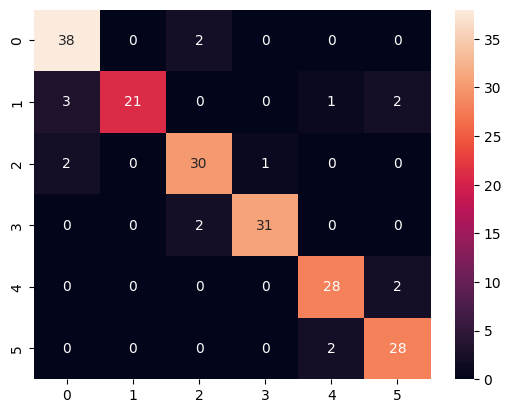

In [7]:
# 6. Convolutional Neural Network (1D for feature data)
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

cnn_model = Sequential([
    Conv1D(32, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], 1)),
    MaxPooling1D(2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])
cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_model.fit(X_train_cnn, y_train, epochs=20, batch_size=16, verbose=0)
cnn_eval = cnn_model.evaluate(X_test_cnn, y_test)
y_pred_cnn = np.argmax(cnn_model.predict(X_test_cnn), axis=1)
evaluate_model(cnn_model, X_test_cnn, y_test)